# Text Classification: Cyberbullying Detection
**CT052-3-M-NLP — Natural Language Processing**

**Students:**
- TP139069 - Muhammad Mahdi Hardi Effendi
- TP131138 - Alieu Bojang

**Objective:** Build an effective Supervised Text Classification model to detect and classify cyberbullying tweets into 6 categories using classical ML algorithms with TF-IDF features.

**Dataset:** [Cyberbullying Classification](https://www.kaggle.com/datasets/andrewmvd/cyberbullying-classification) — 47,692 tweets labelled into 6 balanced classes.

**Models:** Multinomial Naïve Bayes, Logistic Regression (MaxEnt), Linear SVC

---

## 1. Import Libraries

In [1]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Text preprocessing
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Vectorization
from sklearn.feature_extraction.text import TfidfVectorizer

# Models
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Evaluation & Tuning
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Model saving
import pickle

# Download NLTK data
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

print('All libraries imported successfully.')

All libraries imported successfully.


## 2. Load Dataset

In [2]:
# Load the cyberbullying tweets dataset
df = pd.read_csv('cyberbullying_tweets.csv')

# Display basic info
print(f'Dataset shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
df

Dataset shape: (47692, 2)
Columns: ['tweet_text', 'cyberbullying_type']


,tweet_text,cyberbullying_type
0,"In other words #katandandre, your food was cra...",not_cyberbullying
1,Why is #aussietv so white? #MKR #theblock #ImA...,not_cyberbullying
2,@XochitlSuckkks a classy whore? Or more red ve...,not_cyberbullying
3,"@Jason_Gio meh. :P thanks for the heads up, b...",not_cyberbullying
4,@RudhoeEnglish This is an ISIS account pretend...,not_cyberbullying
...,...,...
47687,"Black ppl aren't expected to do anything, depe...",ethnicity
47688,Turner did not withhold his disappointment. Tu...,ethnicity
47689,I swear to God. This dumb nigger bitch. I have...,ethnicity
47690,Yea fuck you RT @therealexel: IF YOURE A NIGGE...,ethnicity


## 3. Exploratory Data Analysis (EDA)

We perform EDA to understand the dataset structure, class distribution, text characteristics, and identify any data quality issues before building our models.

### 3.1 Dataset Overview

In [3]:
# Check data types and missing values
print('=== Data Types ===')
print(df.dtypes)
print(f'\n=== Missing Values ===')
print(df.isnull().sum())
print(f'\n=== Duplicate Rows ===')
print(f'Number of duplicates: {df.duplicated().sum()}')

=== Data Types ===
tweet_text            object
cyberbullying_type    object
dtype: object

=== Missing Values ===
tweet_text            0
cyberbullying_type    0
dtype: int64

=== Duplicate Rows ===
Number of duplicates: 36


In [4]:
# Remove duplicate rows if any
initial_count = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Removed {initial_count - len(df)} duplicate rows.')
print(f'Dataset shape after cleaning: {df.shape}')

Removed 36 duplicate rows.
Dataset shape after cleaning: (47656, 2)


### 3.2 Class Distribution

In [5]:
# Count of tweets per class
class_counts = df['cyberbullying_type'].value_counts()
print('Class Distribution:')
print(class_counts)
print(f'\nClass Balance Ratio (min/max): {class_counts.min() / class_counts.max():.2f}')

Class Distribution:
cyberbullying_type
religion               7997
age                    7992
ethnicity              7959
gender                 7948
not_cyberbullying      7937
other_cyberbullying    7823
Name: count, dtype: int64

Class Balance Ratio (min/max): 0.98


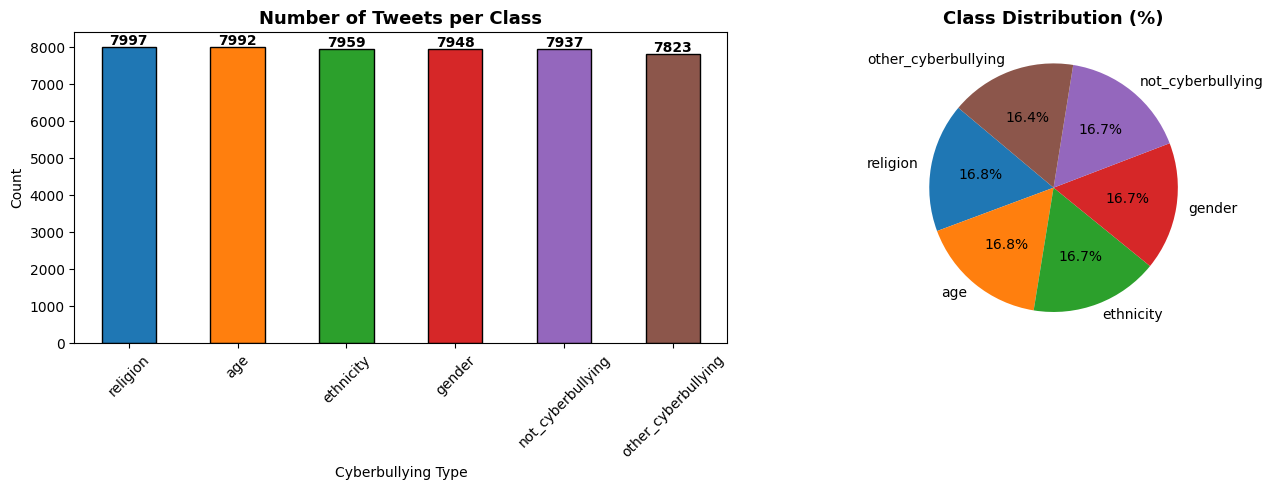

Observation: The dataset is well-balanced across all 6 classes (~8000 tweets each).


In [6]:
# Visualize class distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Use a color palette instead of hardcoded colors
colors = sns.color_palette('tab10', n_colors=len(class_counts))

# Bar chart
class_counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title('Number of Tweets per Class', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Cyberbullying Type')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

# Add count labels on bars
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 50, str(v), ha='center', fontweight='bold', fontsize=10)

# Pie chart
axes[1].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=140)
axes[1].set_title('Class Distribution (%)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print('Observation: The dataset is well-balanced across all 6 classes (~8000 tweets each).')

### 3.3 Text Length Analysis

In [7]:
# Calculate text length (characters) and word count for each tweet
df['text_length'] = df['tweet_text'].str.len()
df['word_count'] = df['tweet_text'].str.split().str.len()

# Summary statistics
print('=== Text Length (Characters) ===')
print(df['text_length'].describe().round(2))
print(f'\n=== Word Count ===')
print(df['word_count'].describe().round(2))

=== Text Length (Characters) ===
count    47656.00
mean       136.26
std         85.25
min          1.00
25%         78.00
50%        124.00
75%        180.00
max       5018.00
Name: text_length, dtype: float64

=== Word Count ===
count    47656.00
mean        23.71
std         15.44
min          1.00
25%         13.00
50%         20.00
75%         32.00
max        790.00
Name: word_count, dtype: float64


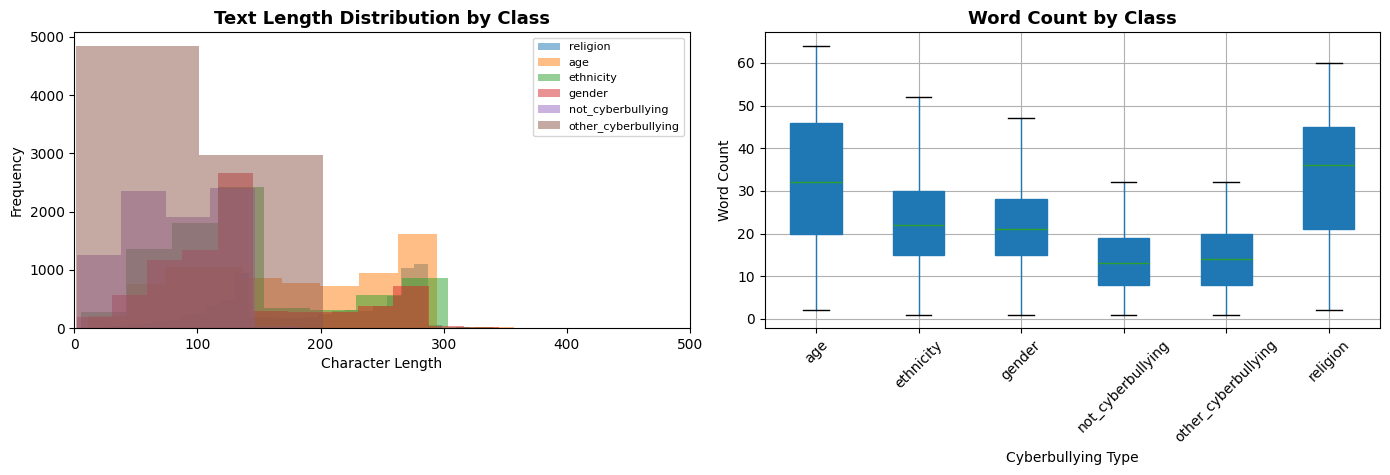

Observation: Most tweets are between 50-200 characters. The classes have similar text length distributions.


In [8]:
# Distribution of text length by class
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of text length
for label, color in zip(class_counts.index, colors):
    subset = df[df['cyberbullying_type'] == label]
    axes[0].hist(subset['text_length'], bins=50, alpha=0.5, label=label, color=color)
axes[0].set_title('Text Length Distribution by Class', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Character Length')
axes[0].set_ylabel('Frequency')
axes[0].legend(fontsize=8)
axes[0].set_xlim(0, 500)  # Focus on main range

# Boxplot of word count per class
df.boxplot(
    column='word_count', by='cyberbullying_type', 
    ax=axes[1], patch_artist=True, 
    showfliers=False
)
axes[1].set_title('Word Count by Class', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Cyberbullying Type')
axes[1].set_ylabel('Word Count')
axes[1].tick_params(axis='x', rotation=45)
plt.suptitle('')  # Remove default title

plt.tight_layout()
plt.show()

print('Observation: Most tweets are between 50-200 characters. The classes have similar text length distributions.')

### 3.4 Most Common Words per Class (Word Clouds)

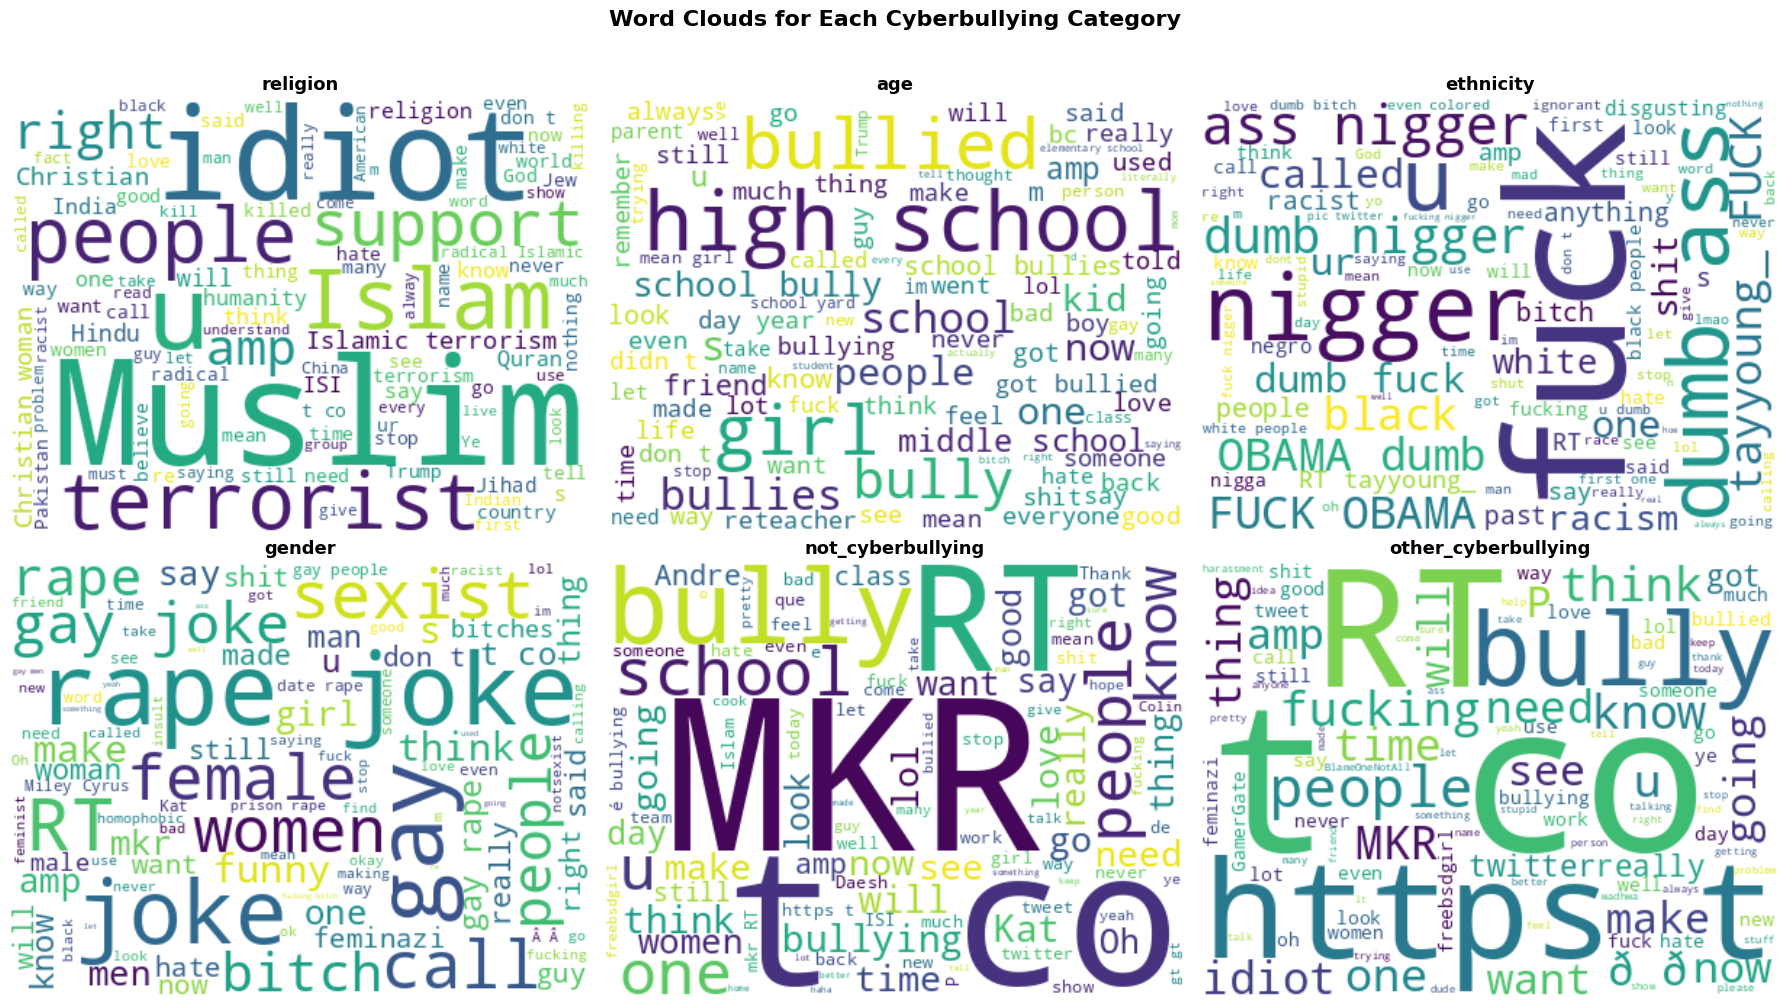

Observation: Each class shows distinct word patterns — e.g., religion-related tweets contain religious terms, gender-related tweets contain gendered language.


In [9]:
from wordcloud import WordCloud

# Generate word cloud for each class
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, label in enumerate(class_counts.index):
    text = ' '.join(df[df['cyberbullying_type'] == label]['tweet_text'].values)
    wordcloud = WordCloud(width=400, height=300, background_color='white',
                          colormap='viridis', max_words=100).generate(text)
    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].set_title(f'{label}', fontsize=13, fontweight='bold')
    axes[i].axis('off')

plt.suptitle('Word Clouds for Each Cyberbullying Category', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('Observation: Each class shows distinct word patterns — e.g., religion-related tweets contain religious terms, gender-related tweets contain gendered language.')

### 3.5 Top Words per Class (Bar Charts)

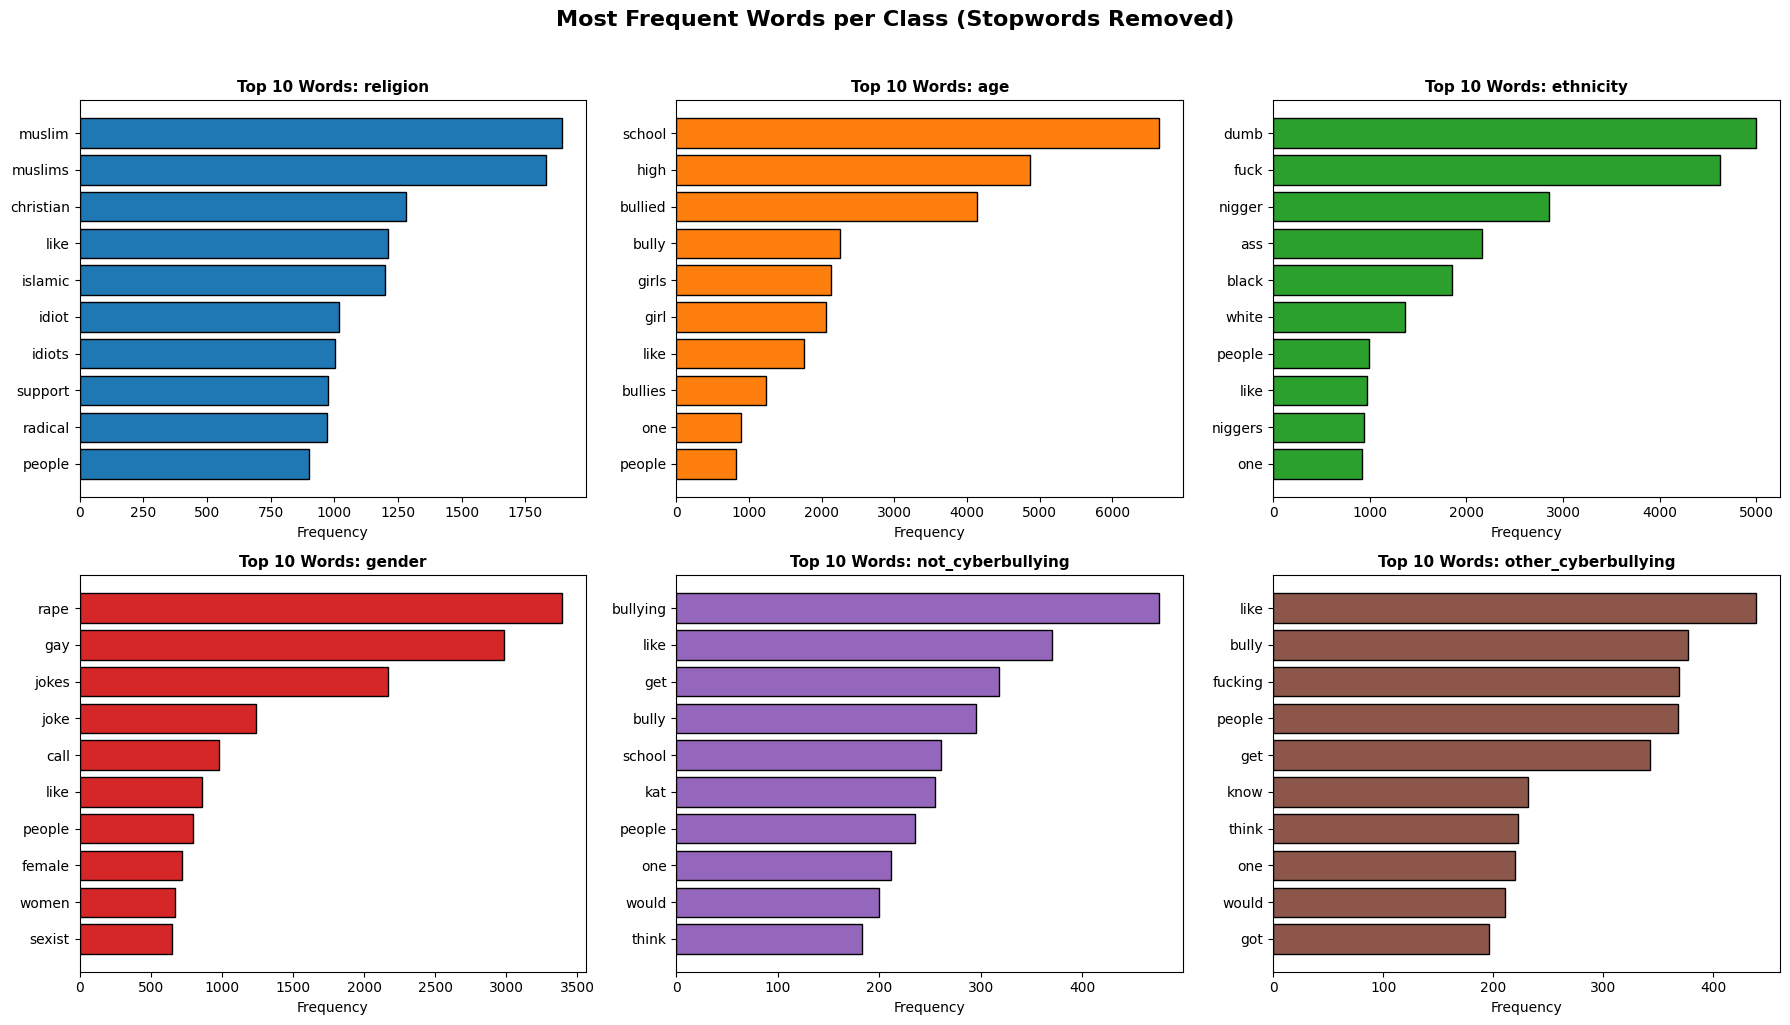

In [10]:
from collections import Counter

# Get top 10 most frequent words per class (excluding stopwords)
stop_words = set(stopwords.words('english'))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, label in enumerate(class_counts.index):
    # Get all words for this class, filter stopwords and short words
    text = ' '.join(df[df['cyberbullying_type'] == label]['tweet_text'].values).lower()
    words = [w for w in text.split() if w not in stop_words and len(w) > 2 and w.isalpha()]
    top_words = Counter(words).most_common(10)
    
    # Plot
    words_list, counts_list = zip(*top_words)
    axes[i].barh(range(len(words_list)), counts_list, color=colors[i], edgecolor='black')
    axes[i].set_yticks(range(len(words_list)))
    axes[i].set_yticklabels(words_list)
    axes[i].invert_yaxis()
    axes[i].set_title(f'Top 10 Words: {label}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Frequency')

plt.suptitle('Most Frequent Words per Class (Stopwords Removed)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 4. Text Preprocessing

Following the standard NLP pipeline from the lecture slides: **lowercase -> remove noise -> tokenize -> remove stopwords -> lemmatize**.

In [11]:
# Initialize the lemmatizer
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def get_wordnet_pos(tag):
    """Convert NLTK POS tag to WordNet POS tag for better lemmatization."""
    if tag.startswith('J'):
        return 'a'  # Adjective
    elif tag.startswith('V'):
        return 'v'  # Verb
    elif tag.startswith('R'):
        return 'r'  # Adverb
    else:
        return 'n'  # Default to Noun

def preprocess_text(text):
    """Clean and preprocess a tweet for classification."""
    # 1. Lowercase
    text = text.lower()
    
    # 2. Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    
    # 3. Remove @mentions and #hashtags symbols (keep the text after #)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#', '', text)
    
    # 4. Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    # 5. Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    
    # 6. Tokenize using NLTK word_tokenize
    tokens = word_tokenize(text)
    
    # 7. POS tagging — identifies each word's part of speech
    tagged_tokens = nltk.pos_tag(tokens)
    
    # 8. Remove stopwords and lemmatize with POS-aware lemmatization
    tokens = [lemmatizer.lemmatize(word, pos=get_wordnet_pos(tag))
              for word, tag in tagged_tokens
              if word not in stop_words and len(word) > 2]
    
    return ' '.join(tokens)

# Apply preprocessing to all tweets
print('Preprocessing tweets (with POS tagging)...')
df['cleaned_text'] = df['tweet_text'].apply(preprocess_text)
print('Done!')

# Show before and after examples
print('\n=== Before and After Preprocessing ===')
for i in [0, 5, 100]:
    print(f'\nOriginal:  {df["tweet_text"].iloc[i][:100]}...')
    print(f'Cleaned:   {df["cleaned_text"].iloc[i][:100]}')

Preprocessing tweets (with POS tagging)...
Done!

=== Before and After Preprocessing ===

Original:  In other words #katandandre, your food was crapilicious! #mkr...
Cleaned:   word katandandre food crapilicious mkr

Original:  @Raja5aab @Quickieleaks Yes, the test of god is that good or bad or indifferent or weird or whatever...
Cleaned:   yes test god good bad indifferent weird whatever prove god existence

Original:  @mirebotan84 @RamiAlLolah I support that. I don't like people like Rami who complain about the thing...
Cleaned:   support dont like people like ramus complain thing support do others


In [12]:
# Remove any rows where cleaned text is empty after preprocessing
empty_count = (df['cleaned_text'].str.strip() == '').sum()
print(f'Empty rows after preprocessing: {empty_count}')

if empty_count > 0:
    df = df[df['cleaned_text'].str.strip() != ''].reset_index(drop=True)
    print(f'Dataset shape after removing empty rows: {df.shape}')

Empty rows after preprocessing: 458
Dataset shape after removing empty rows: (47198, 5)


---
## 5. Feature Extraction — TF-IDF Vectorization

We use **TF-IDF (Term Frequency — Inverse Document Frequency)** to convert text into numerical features. TF-IDF downweights common words and upweights distinctive words, which generally outperforms plain CountVectorizer (Bag of Words).

$$\text{TF-IDF}(t, d) = \text{TF}(t,d) \times \log\left(\frac{N}{\text{DF}(t)}\right)$$

In [13]:
# Define features (X) and target (y)
X = df['cleaned_text']
y = df['cyberbullying_type']

# Split into training (80%) and testing (20%) sets — stratified to maintain class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set: {X_train.shape[0]} samples')
print(f'Testing set:  {X_test.shape[0]} samples')
print(f'\nClass distribution in training set:')
print(y_train.value_counts())

Training set: 37758 samples
Testing set:  9440 samples

Class distribution in training set:
cyberbullying_type
religion               6397
age                    6394
ethnicity              6366
gender                 6331
not_cyberbullying      6228
other_cyberbullying    6042
Name: count, dtype: int64


In [14]:
# Apply TF-IDF vectorization
# max_features=10000 limits to the top 10K most important words
# ngram_range=(1,2) includes both unigrams and bigrams for better context
tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))

# Fit on training data only, then transform both train and test
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f'TF-IDF matrix shape (train): {X_train_tfidf.shape}')
print(f'TF-IDF matrix shape (test):  {X_test_tfidf.shape}')
print(f'Vocabulary size: {len(tfidf.vocabulary_)}')

TF-IDF matrix shape (train): (37758, 10000)
TF-IDF matrix shape (test):  (9440, 10000)
Vocabulary size: 10000


In [15]:
print(X_train_tfidf)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 499838 stored elements and shape (37758, 10000)>
  Coords	Values
  (0, 7910)	0.21682193682557854
  (0, 3481)	0.1460846354864051
  (0, 667)	0.352463128000659
  (0, 9514)	0.26305494137743374
  (0, 2281)	0.15543366221073532
  (0, 3359)	0.14444881698165116
  (0, 7808)	0.18449387541978882
  (0, 3756)	0.2118870013064417
  (0, 5164)	0.1953331893968221
  (0, 7918)	0.38109476663633546
  (0, 2307)	0.30424607608110105
  (0, 7819)	0.40031101047266127
  (0, 3769)	0.42196840732843816
  (1, 8936)	0.3165142691386867
  (1, 1447)	0.34916159880228737
  (1, 4896)	0.5505404273830029
  (1, 6360)	0.3833922491628789
  (1, 8605)	0.19700440021575566
  (1, 6611)	0.2989111176598829
  (1, 5573)	0.3466070553550718
  (1, 4835)	0.28200261641559166
  (2, 7808)	0.12079785288382623
  (2, 8605)	0.1325336864704869
  (2, 1309)	0.12926552322801194
  (2, 651)	0.16284082917973383
  :	:
  (37754, 3571)	0.3010823914472536
  (37754, 1198)	0.4167121667087997
  (37754, 

## 6. Model Building & Evaluation

We build **3 classifiers** as required:
1. **Multinomial Naïve Bayes (MNB)** — Generative probabilistic classifier based on Bayes' theorem
2. **Logistic Regression (MaxEnt)** — Discriminative linear classifier  
3. **Linear SVC** — Maximum-margin linear classifier

Each model is evaluated using **Stratified 5-Fold Cross-Validation** on the training set, then tested on the held-out test set.

In [16]:
# Helper function to evaluate a trained model and display results
def evaluate_model(model, model_name, X_test, y_test):
    """Display evaluation metrics and confusion matrix for a trained model."""
    
    # --- Predict on test set ---
    y_pred = model.predict(X_test)
    
    # --- Metrics ---
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    print(f'=== {model_name} ===')
    print(f'Test Accuracy: {acc:.4f}')
    print(f'Test F1 (macro): {f1:.4f}')
    
    # --- Classification Report ---
    print(f'\nClassification Report:')
    print(classification_report(y_test, y_pred))
    
    # --- Confusion Matrix ---
    cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=model.classes_, yticklabels=model.classes_)
    plt.title(f'Confusion Matrix — {model_name}', fontsize=13, fontweight='bold')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    
    return {'model': model, 'name': model_name, 'accuracy': acc,
            'f1_macro': f1, 'y_pred': y_pred}

### 6.1 Model 1: Multinomial Naïve Bayes

=== Training Result ===
Train Accuracy: 0.8232
Test Accuracy:  0.7744

=== Cross-Validation ===
CV F1 (macro): 0.7563 (+/- 0.0008)
=== Multinomial Naïve Bayes ===
Test Accuracy: 0.7744
Test F1 (macro): 0.7599

Classification Report:
                     precision    recall  f1-score   support

                age       0.81      0.97      0.88      1598
          ethnicity       0.89      0.92      0.91      1591
             gender       0.86      0.78      0.82      1583
  not_cyberbullying       0.64      0.43      0.52      1557
other_cyberbullying       0.59      0.55      0.57      1511
           religion       0.78      0.97      0.87      1600

           accuracy                           0.77      9440
          macro avg       0.76      0.77      0.76      9440
       weighted avg       0.76      0.77      0.76      9440



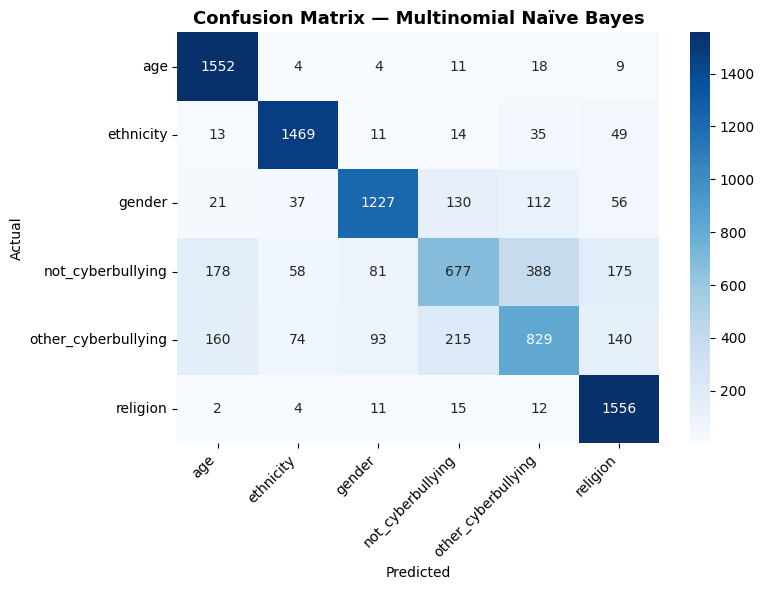

In [17]:
# --- Multinomial Naïve Bayes ---
# Classic baseline for text classification — uses Bayes' theorem with conditional independence assumption
mnb_model = MultinomialNB()

# Train on full training set
mnb_model.fit(X_train_tfidf, y_train)

# Check performance after training
print('=== Training Result ===')
print(f'Train Accuracy: {mnb_model.score(X_train_tfidf, y_train):.4f}')
print(f'Test Accuracy:  {mnb_model.score(X_test_tfidf, y_test):.4f}')

# Cross-Validation to check model stability (trains & evaluates on 5 different splits)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mnb_cv_scores = cross_val_score(MultinomialNB(), X_train_tfidf, y_train, cv=cv, scoring='f1_macro')
print(f'\n=== Cross-Validation ===')
print(f'CV F1 (macro): {mnb_cv_scores.mean():.4f} (+/- {mnb_cv_scores.std():.4f})')

# Full evaluation on test set (classification report + confusion matrix)
mnb_results = evaluate_model(mnb_model, 'Multinomial Naïve Bayes', X_test_tfidf, y_test)
mnb_results['cv_f1_mean'] = mnb_cv_scores.mean()

### 6.2 Model 2: Logistic Regression (Maximum Entropy)

=== Training Result ===
Train Accuracy: 0.8857
Test Accuracy:  0.8244

=== Cross-Validation ===
CV F1 (macro): 0.8229 (+/- 0.0025)
=== Logistic Regression ===
Test Accuracy: 0.8244
Test F1 (macro): 0.8225

Classification Report:
                     precision    recall  f1-score   support

                age       0.95      0.97      0.96      1598
          ethnicity       0.97      0.98      0.97      1591
             gender       0.91      0.83      0.87      1583
  not_cyberbullying       0.59      0.54      0.56      1557
other_cyberbullying       0.58      0.67      0.62      1511
           religion       0.95      0.95      0.95      1600

           accuracy                           0.82      9440
          macro avg       0.83      0.82      0.82      9440
       weighted avg       0.83      0.82      0.83      9440



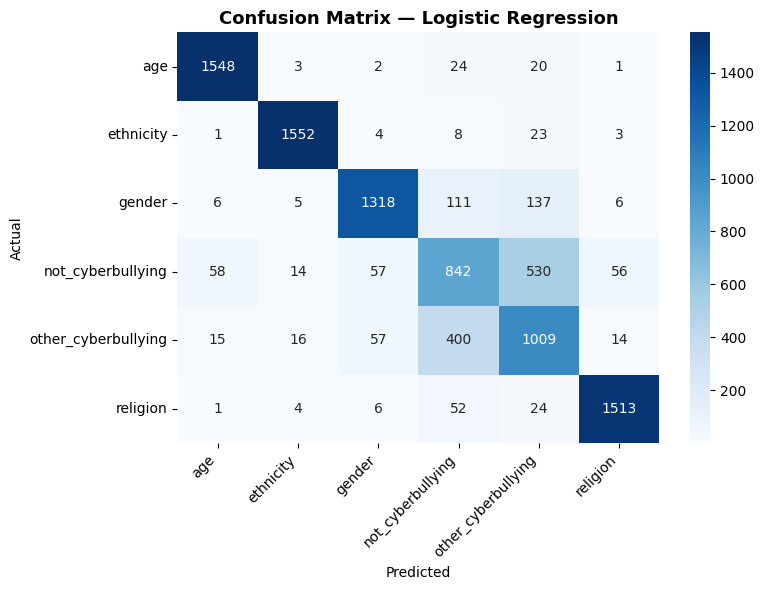

In [18]:
# --- Logistic Regression (Maximum Entropy) ---
# Discriminative classifier that models P(c|d) directly
# max_iter=1000 ensures convergence for high-dimensional TF-IDF features
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# Train on full training set
lr_model.fit(X_train_tfidf, y_train)

# Check performance after training
print('=== Training Result ===')
print(f'Train Accuracy: {lr_model.score(X_train_tfidf, y_train):.4f}')
print(f'Test Accuracy:  {lr_model.score(X_test_tfidf, y_test):.4f}')

# Cross-Validation to check model stability (trains & evaluates on 5 different splits)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr_cv_scores = cross_val_score(LogisticRegression(max_iter=1000, random_state=42),
                               X_train_tfidf, y_train, cv=cv, scoring='f1_macro')
print(f'\n=== Cross-Validation ===')
print(f'CV F1 (macro): {lr_cv_scores.mean():.4f} (+/- {lr_cv_scores.std():.4f})')

# Full evaluation on test set (classification report + confusion matrix)
lr_results = evaluate_model(lr_model, 'Logistic Regression', X_test_tfidf, y_test)
lr_results['cv_f1_mean'] = lr_cv_scores.mean()

### 6.3 Model 3: Linear SVC (Support Vector Classifier)

=== Training Result ===
Train Accuracy: 0.9205
Test Accuracy:  0.8174

=== Cross-Validation ===
CV F1 (macro): 0.8127 (+/- 0.0023)
=== Linear SVC ===
Test Accuracy: 0.8174
Test F1 (macro): 0.8135

Classification Report:
                     precision    recall  f1-score   support

                age       0.94      0.97      0.95      1598
          ethnicity       0.96      0.98      0.97      1591
             gender       0.88      0.85      0.87      1583
  not_cyberbullying       0.57      0.53      0.55      1557
other_cyberbullying       0.58      0.61      0.59      1511
           religion       0.95      0.95      0.95      1600

           accuracy                           0.82      9440
          macro avg       0.81      0.81      0.81      9440
       weighted avg       0.82      0.82      0.82      9440



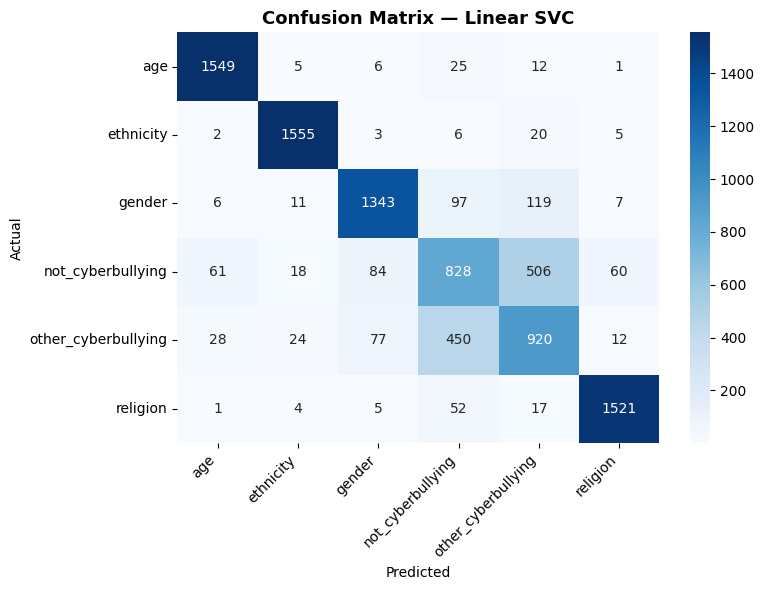

In [19]:
# --- Linear SVC (Support Vector Classifier) ---
# Finds the maximum-margin hyperplane separating classes
# Often the best performer for text classification (high-dimensional sparse data)
svc_model = LinearSVC(max_iter=2000, random_state=42)

# Train on full training set
svc_model.fit(X_train_tfidf, y_train)

# Check performance after training
print('=== Training Result ===')
print(f'Train Accuracy: {svc_model.score(X_train_tfidf, y_train):.4f}')
print(f'Test Accuracy:  {svc_model.score(X_test_tfidf, y_test):.4f}')

# Cross-Validation to check model stability (trains & evaluates on 5 different splits)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
svc_cv_scores = cross_val_score(
                    LinearSVC(max_iter=2000, random_state=42),
                    X_train_tfidf, y_train, cv=cv, scoring='f1_macro'
                )
print(f'\n=== Cross-Validation ===')
print(f'CV F1 (macro): {svc_cv_scores.mean():.4f} (+/- {svc_cv_scores.std():.4f})')

# Full evaluation on test set (classification report + confusion matrix)
svc_results = evaluate_model(svc_model, 'Linear SVC', X_test_tfidf, y_test)
svc_results['cv_f1_mean'] = svc_cv_scores.mean()

### 6.4 Model Comparison

=== Model Comparison ===
                  Model  CV F1 (mean)  Test Accuracy  Test F1 (macro)
Multinomial Naïve Bayes      0.756268       0.774364         0.759920
    Logistic Regression      0.822922       0.824364         0.822520
             Linear SVC      0.812742       0.817373         0.813503


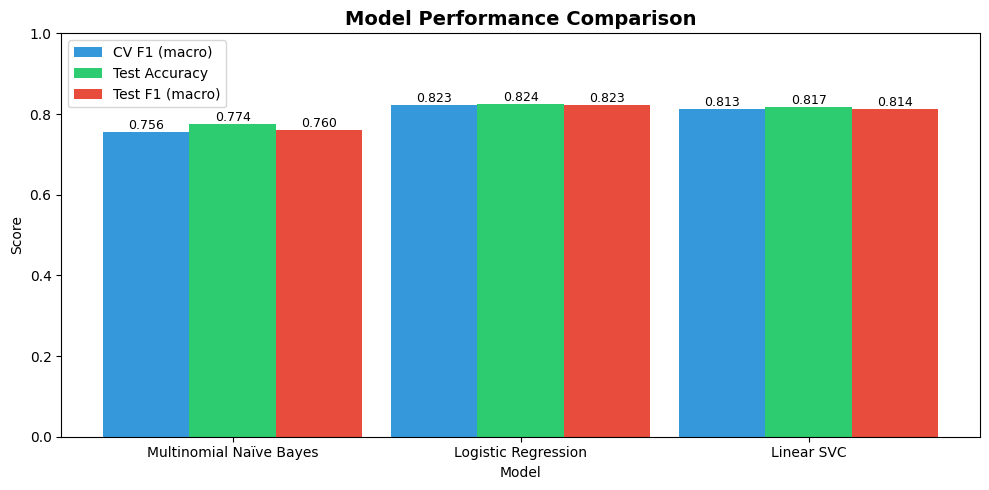

In [20]:
# Compare all three models side by side
results_list = [mnb_results, lr_results, svc_results]

comparison_df = pd.DataFrame({
    'Model': [r['name'] for r in results_list],
    'CV F1 (mean)': [r['cv_f1_mean'] for r in results_list],
    'Test Accuracy': [r['accuracy'] for r in results_list],
    'Test F1 (macro)': [r['f1_macro'] for r in results_list]
})

print('=== Model Comparison ===')
print(comparison_df.to_string(index=False))

# Visualize comparison
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(comparison_df))
width = 0.3

ax.bar(x - width, comparison_df['CV F1 (mean)'], width, label='CV F1 (macro)', color='#3498db')
ax.bar(x, comparison_df['Test Accuracy'], width, label='Test Accuracy', color='#2ecc71')
ax.bar(x + width, comparison_df['Test F1 (macro)'], width, label='Test F1 (macro)', color='#e74c3c')

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Model'])
ax.legend()
ax.set_ylim(0, 1)

# Add value labels
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.3f', fontsize=9)

plt.tight_layout()
plt.show()

---
## 7. Hyperparameter Tuning

We tune the **best-performing model** using **GridSearchCV** with Stratified 5-Fold Cross-Validation to find the optimal hyperparameters.

In [21]:
# Identify the best model based on test F1 (macro)
best_result = max(results_list, key=lambda r: r['f1_macro'])
print(f'Best performing model: {best_result["name"]} (F1 macro: {best_result["f1_macro"]:.4f})')
print('\nProceeding with hyperparameter tuning...')

Best performing model: Logistic Regression (F1 macro: 0.8225)

Proceeding with hyperparameter tuning...


### 7.1 Tuning Multinomial Naïve Bayes

In [22]:
# Tune MNB — the key hyperparameter is alpha (smoothing)
mnb_param_grid = {
    'alpha': [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0]
}

mnb_grid = GridSearchCV(
    MultinomialNB(), mnb_param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_macro', n_jobs=-1, verbose=1
)

mnb_grid.fit(X_train_tfidf, y_train)

print(f'Best parameters: {mnb_grid.best_params_}')
print(f'Best CV F1 (macro): {mnb_grid.best_score_:.4f}')

# Evaluate tuned model on test set
y_pred_mnb_tuned = mnb_grid.predict(X_test_tfidf)
print(f'\nTuned Test F1 (macro): {f1_score(y_test, y_pred_mnb_tuned, average="macro"):.4f}')
print(f'Tuned Test Accuracy:   {accuracy_score(y_test, y_pred_mnb_tuned):.4f}')

Fitting 5 folds for each of 7 candidates, totalling 35 fits
Best parameters: {'alpha': 0.5}
Best CV F1 (macro): 0.7569

Tuned Test F1 (macro): 0.7630
Tuned Test Accuracy:   0.7754


### 7.2 Tuning Logistic Regression

In [23]:
# Tune Logistic Regression — C, solver, and penalty
lr_param_grid = [
    {
        'solver': ['lbfgs'],
        'penalty': ['l2'],
        'C': [0.01, 0.1, 0.5, 1, 5, 10, 50]
    },
    {
        'solver': ['saga'],
        'penalty': ['l1', 'l2'],
        'C': [0.01, 0.1, 0.5, 1, 5, 10, 50]
    }
]

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42), lr_param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_macro', n_jobs=-1, verbose=1
)

lr_grid.fit(X_train_tfidf, y_train)

print(f'Best parameters: {lr_grid.best_params_}')
print(f'Best CV F1 (macro): {lr_grid.best_score_:.4f}')

# Evaluate tuned model on test set
y_pred_lr_tuned = lr_grid.predict(X_test_tfidf)
print(f'\nTuned Test F1 (macro): {f1_score(y_test, y_pred_lr_tuned, average="macro"):.4f}')
print(f'Tuned Test Accuracy:   {accuracy_score(y_test, y_pred_lr_tuned):.4f}')

Fitting 5 folds for each of 21 candidates, totalling 105 fits
Best parameters: {'C': 1, 'penalty': 'l2', 'solver': 'saga'}
Best CV F1 (macro): 0.8232

Tuned Test F1 (macro): 0.8227
Tuned Test Accuracy:   0.8245


### 7.3 Tuning Linear SVC

In [24]:
# Tune Linear SVC — C (regularization), loss function, and class weight
svc_param_grid = [
    {
        'C': [0.01, 0.1, 0.5, 1, 5, 10, 50],
        'loss': ['squared_hinge'],
        'penalty': ['l1', 'l2'],
        'dual': [False],  # l1 penalty requires dual=False
        'class_weight': [None, 'balanced']
    },
    {
        'C': [0.01, 0.1, 0.5, 1, 5, 10, 50],
        'loss': ['hinge'],
        'penalty': ['l2'],  # hinge only supports l2
        'class_weight': [None, 'balanced']
    }
]

svc_grid = GridSearchCV(
    LinearSVC(max_iter=2000, random_state=42), svc_param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_macro', n_jobs=-1, verbose=1
)

svc_grid.fit(X_train_tfidf, y_train)

print(f'Best parameters: {svc_grid.best_params_}')
print(f'Best CV F1 (macro): {svc_grid.best_score_:.4f}')

# Evaluate tuned model on test set
y_pred_svc_tuned = svc_grid.predict(X_test_tfidf)
print(f'\nTuned Test F1 (macro): {f1_score(y_test, y_pred_svc_tuned, average="macro"):.4f}')
print(f'Tuned Test Accuracy:   {accuracy_score(y_test, y_pred_svc_tuned):.4f}')

Fitting 5 folds for each of 42 candidates, totalling 210 fits
Best parameters: {'C': 0.1, 'class_weight': None, 'dual': False, 'loss': 'squared_hinge', 'penalty': 'l2'}
Best CV F1 (macro): 0.8243

Tuned Test F1 (macro): 0.8242
Tuned Test Accuracy:   0.8286


### 7.4 Tuned Model Comparison

In [25]:
# Compare all tuned models
tuned_comparison = pd.DataFrame({
    'Model': ['MNB (Tuned)', 'Logistic Regression (Tuned)', 'Linear SVC (Tuned)'],
    'Best Params': [str(mnb_grid.best_params_), str(lr_grid.best_params_), str(svc_grid.best_params_)],
    'CV F1 (macro)': [mnb_grid.best_score_, lr_grid.best_score_, svc_grid.best_score_],
    'Test F1 (macro)': [
        f1_score(y_test, y_pred_mnb_tuned, average='macro'),
        f1_score(y_test, y_pred_lr_tuned, average='macro'),
        f1_score(y_test, y_pred_svc_tuned, average='macro')
    ],
    'Test Accuracy': [
        accuracy_score(y_test, y_pred_mnb_tuned),
        accuracy_score(y_test, y_pred_lr_tuned),
        accuracy_score(y_test, y_pred_svc_tuned)
    ]
})

print('=== Tuned Model Comparison ===')
print(tuned_comparison.to_string(index=False))

# Identify the overall best model
best_idx = tuned_comparison['Test F1 (macro)'].idxmax()
print(f'\n*** Best Overall Model: {tuned_comparison.loc[best_idx, "Model"]} ***')
print(f'    Test F1 (macro): {tuned_comparison.loc[best_idx, "Test F1 (macro)"]:.4f}')
print(f'    Test Accuracy:   {tuned_comparison.loc[best_idx, "Test Accuracy"]:.4f}')

=== Tuned Model Comparison ===
                      Model                                                                               Best Params  CV F1 (macro)  Test F1 (macro)  Test Accuracy
                MNB (Tuned)                                                                            {'alpha': 0.5}       0.756900         0.762957       0.775424
Logistic Regression (Tuned)                                               {'C': 1, 'penalty': 'l2', 'solver': 'saga'}       0.823183         0.822658       0.824470
         Linear SVC (Tuned) {'C': 0.1, 'class_weight': None, 'dual': False, 'loss': 'squared_hinge', 'penalty': 'l2'}       0.824324         0.824188       0.828602

*** Best Overall Model: Linear SVC (Tuned) ***
    Test F1 (macro): 0.8242
    Test Accuracy:   0.8286


=== Final Classification Report — Linear SVC (Tuned) ===
                     precision    recall  f1-score   support

                age       0.93      0.98      0.96      1598
          ethnicity       0.96      0.98      0.97      1591
             gender       0.91      0.83      0.87      1583
  not_cyberbullying       0.62      0.51      0.56      1557
other_cyberbullying       0.59      0.69      0.64      1511
           religion       0.94      0.96      0.95      1600

           accuracy                           0.83      9440
          macro avg       0.83      0.83      0.82      9440
       weighted avg       0.83      0.83      0.83      9440



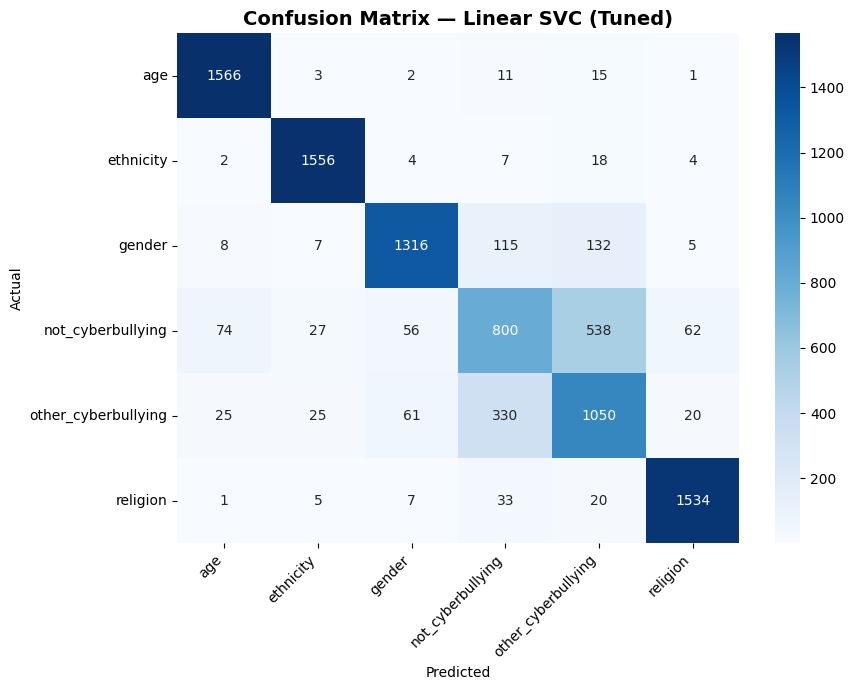

In [26]:
# Final classification report and confusion matrix for the best tuned model
# Select the best grid search object
grids = [mnb_grid, lr_grid, svc_grid]
best_grid = grids[best_idx]
best_preds = [y_pred_mnb_tuned, y_pred_lr_tuned, y_pred_svc_tuned][best_idx]

print(f'=== Final Classification Report — {tuned_comparison.loc[best_idx, "Model"]} ===')
print(classification_report(y_test, best_preds))

# Confusion matrix
cm = confusion_matrix(y_test, best_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=best_grid.classes_, yticklabels=best_grid.classes_)
plt.title(f'Confusion Matrix — {tuned_comparison.loc[best_idx, "Model"]}',
          fontsize=14, fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

---
## 8. Save the Best Model

We save both the **trained model** and the **TF-IDF vectorizer** using pickle, so they can be loaded later for deployment.

In [27]:
# Save the best tuned model
with open('best_model.pkl', 'wb') as f:
    pickle.dump(best_grid.best_estimator_, f)

# Save the TF-IDF vectorizer (needed to transform new input at prediction time)
with open('tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

print('Model and vectorizer saved successfully!')
print(f'  - best_model.pkl ({tuned_comparison.loc[best_idx, "Model"]})')
print(f'  - tfidf_vectorizer.pkl')

Model and vectorizer saved successfully!
  - best_model.pkl (Linear SVC (Tuned))
  - tfidf_vectorizer.pkl


---
## 9. Quick Test — Predict on New Text

In [28]:
# Load the saved model and vectorizer
with open('best_model.pkl', 'rb') as f:
    loaded_model = pickle.load(f)
with open('tfidf_vectorizer.pkl', 'rb') as f:
    loaded_tfidf = pickle.load(f)

# Test with sample inputs
test_texts = [
    "You're so old, go back to the retirement home",
    "Women belong in the kitchen not in the office",
    "All muslims are terrorists",
    "I love playing football with my friends on weekends",
    "Go back to your country you don't belong here",
    "Fuck you moron, you are a disgrace nigger"
]

print('=== Predictions on Sample Texts ===')
for text in test_texts:
    # Preprocess → Vectorize → Predict
    cleaned = preprocess_text(text)
    vectorized = loaded_tfidf.transform([cleaned])
    prediction = loaded_model.predict(vectorized)[0]
    print(f'\nText: "{text}"')
    print(f'Prediction: {prediction}')

=== Predictions on Sample Texts ===

Text: "You're so old, go back to the retirement home"
Prediction: not_cyberbullying

Text: "Women belong in the kitchen not in the office"
Prediction: not_cyberbullying

Text: "All muslims are terrorists"
Prediction: religion

Text: "I love playing football with my friends on weekends"
Prediction: not_cyberbullying

Text: "Go back to your country you don't belong here"
Prediction: religion

Text: "Fuck you moron, you are a disgrace nigger"
Prediction: ethnicity


In [30]:
X_test, y_test

(36485                  park middle school bully reform lol
 31099                 see clapbacks may reach level bad as
 41394    cant fuck wit white people say nigga nigger ma...
 12937    love gay rape joke hahahaha especially locker ...
 2215                         mkr lady love sound crackling
                                ...                        
 15675    joke eat horse meat give license make joke war...
 27620                                                north
 20907    irrelevant please try talk issue raise dear do...
 11801    dont mean gender mean bitch hoe youd get troub...
 12329    want everyone know pretty face noone say prett...
 Name: cleaned_text, Length: 9440, dtype: object,
 36485                    age
 31099    other_cyberbullying
 41394              ethnicity
 12937                 gender
 2215       not_cyberbullying
                 ...         
 15675                 gender
 27620    other_cyberbullying
 20907               religion
 11801              

---
## 10. Summary

In this notebook, we:

1. **Loaded and explored** the Cyberbullying Classification dataset (47K+ tweets, 6 classes)
2. **Performed EDA** — class distribution, text length analysis, word clouds, and top words per class
3. **Preprocessed** the text — lowercasing, URL/mention removal, punctuation removal, stopword removal, and lemmatization
4. **Vectorized** the text using TF-IDF with unigrams and bigrams
5. **Built 3 classifiers** — MNB, Logistic Regression, and Linear SVC — all evaluated with Stratified 5-Fold CV
6. **Tuned hyperparameters** using GridSearchCV for all 3 models
7. **Saved** the best model and vectorizer for deployment

The best performing model will be deployed as a **Streamlit web application** in the next step.